# 01 - Data acquisition & exploratory data analysis

Dataset: **UCI Heart Disease - Cleveland subset** (303 patients, 13 clinical attributes + diagnosis `num`).

All plotting logic lives in `heart_risk/eda.py`, so the figures in this notebook are identical to the ones produced by `python -m heart_risk.eda` and used in the report.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.width", 140)

## 1. Acquire the data
`build_clean_dataset()` downloads `processed.cleveland.data` from the UCI repository (skipped if already on disk), cleans it and writes `data/processed/heart_clean.csv`.

In [2]:
from heart_risk import data, config, eda
clean = data.build_clean_dataset()
raw = data.load_raw()
print(raw.shape, clean.shape)
raw.head()

(303, 14) (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Data quality
* `?` placeholders in the raw file -> NaN (only `ca` and `thal`).
* Out-of-range / invalid codes -> NaN (none found in Cleveland, but the rule protects the pipeline).
* Missing values are **imputed inside the sklearn pipeline** (median / most-frequent), so the same logic runs at training and serving time and the test split never leaks into the imputer.

In [3]:
print('dtypes:'); print(clean.dtypes.value_counts())
print('\nmissing per column:', data.missing_report(clean).to_dict())
print('duplicates:', clean.duplicated().sum())
eda.summary_table(clean)

dtypes:
float64    10
int64       4
Name: count, dtype: int64

missing per column: {'ca': 4, 'thal': 2}
duplicates: 0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2
ca,299.0,0.67,0.94,0.0,0.0,0.0,1.0,3.0


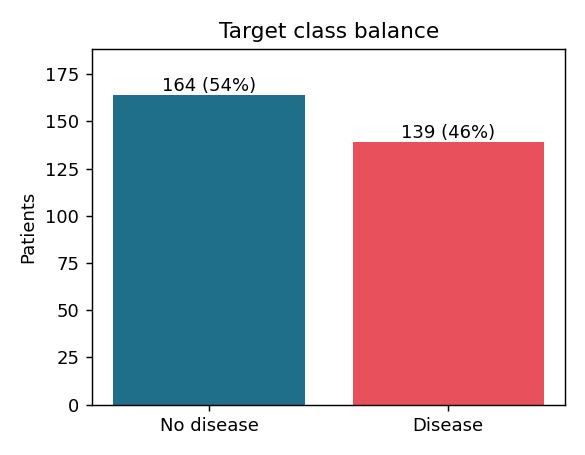

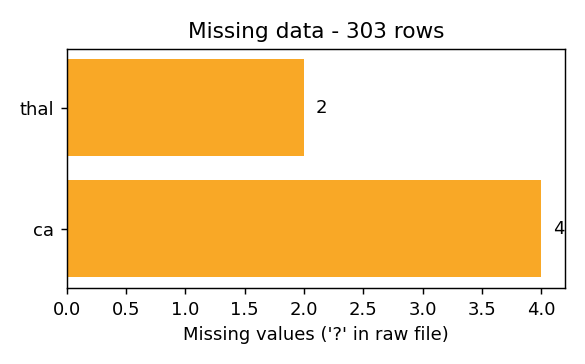

In [4]:
from IPython.display import Image, display
paths = eda.run_all()
for p in paths[:2]:
    display(Image(filename=str(p)))

**Class balance:** 164 healthy vs 139 diseased (54/46 %). The imbalance is mild, so plain stratified splitting is enough; `class_weight='balanced'` is still included in the tuning grid.

## 3. Distributions

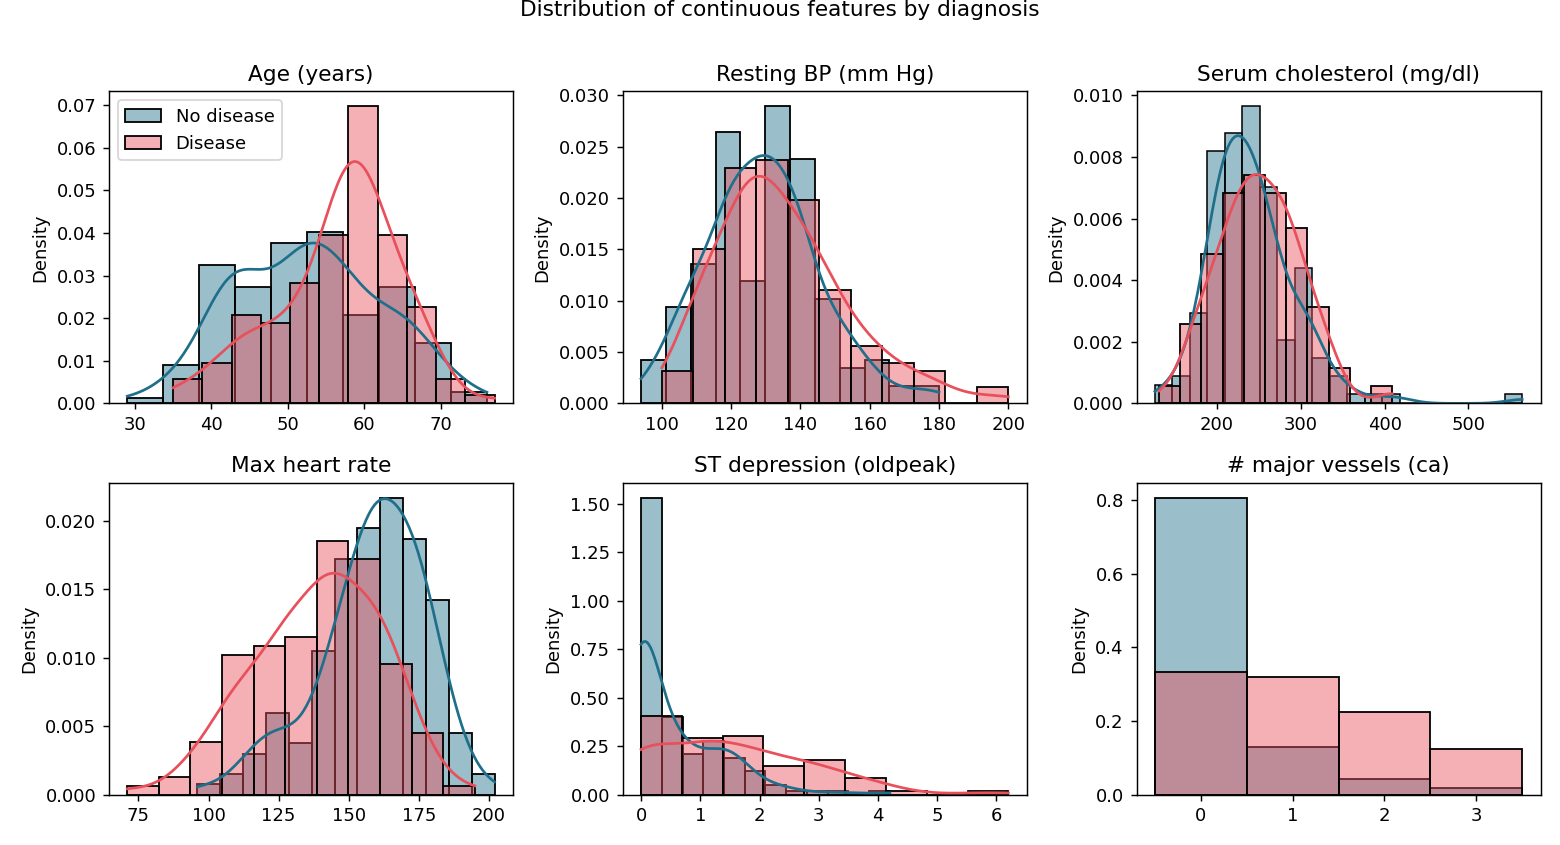

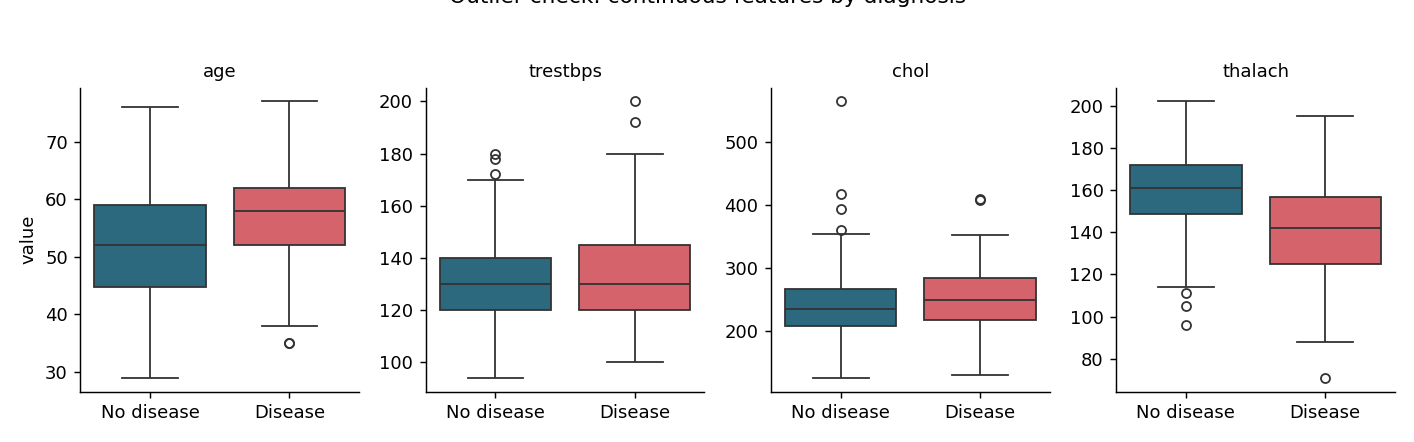

In [5]:
display(Image(filename=str(paths[2])))
display(Image(filename=str(paths[5])))

* Diseased patients reach a clearly **lower max heart rate** (`thalach`) and have **higher ST depression** (`oldpeak`).
* `chol` and `trestbps` overlap heavily -> weak individual signal.
* A few cholesterol outliers (~560 mg/dl) are physiologically possible, so they are kept; `StandardScaler` + regularised models are robust enough for them.

## 4. Correlations and categorical risk

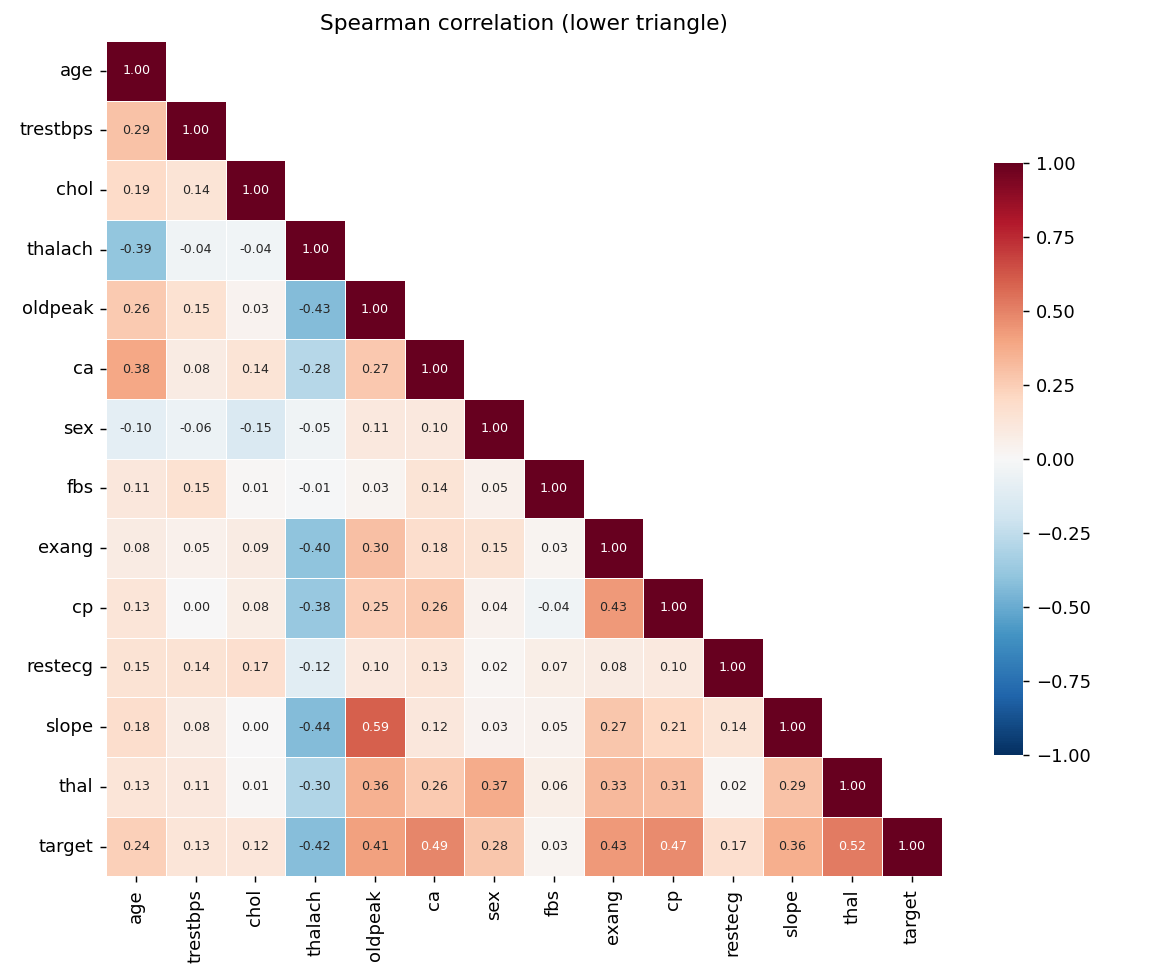

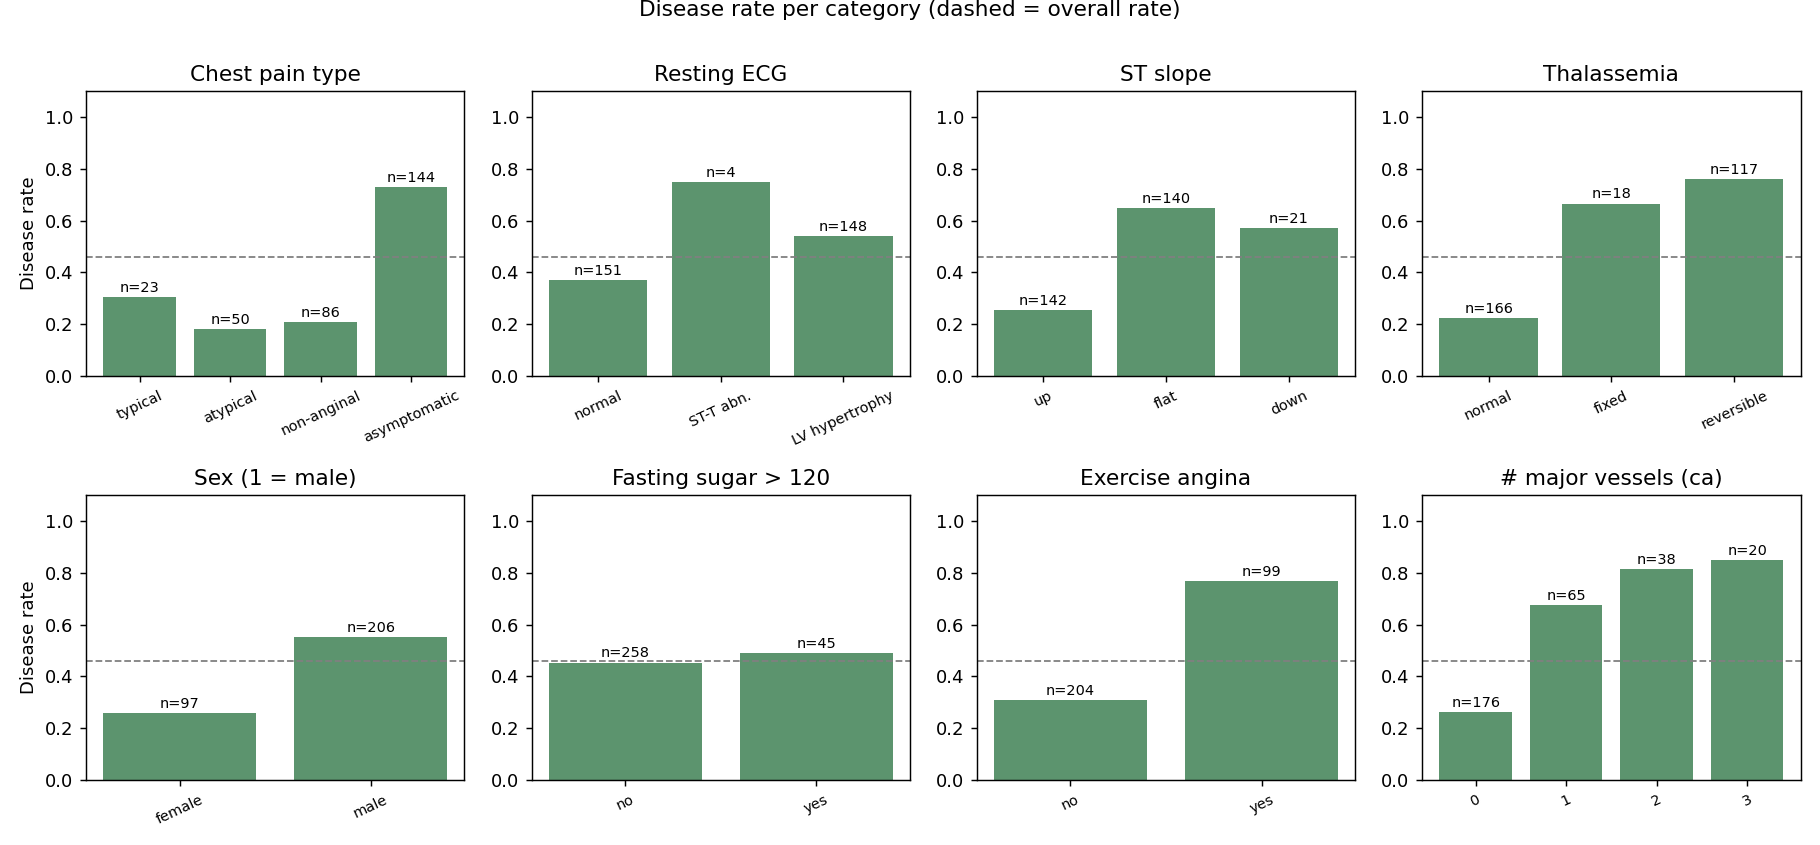

In [6]:
display(Image(filename=str(paths[3])))
display(Image(filename=str(paths[4])))

In [7]:
corr = clean.corr(method='spearman')['target'].drop('target')
corr.sort_values(key=abs, ascending=False).round(3)

thal        0.522
ca          0.489
cp          0.472
exang       0.432
thalach    -0.423
oldpeak     0.413
slope       0.364
sex         0.277
age         0.237
restecg     0.169
trestbps    0.128
chol        0.121
fbs         0.025
Name: target, dtype: float64

* Strongest associations with the target: `thal`, `ca`, `cp`, `oldpeak`, `exang`, `thalach`.
* `cp`, `restecg`, `slope`, `thal` are **nominal codes** (e.g. cp=4 'asymptomatic' carries the highest risk, not a linear 4x effect) -> one-hot encoded.
* `ca` (0-3 vessels) is ordinal with a monotonic risk increase -> kept numeric and scaled.
* `fbs` is almost uninformative but kept (cheap, clinically standard).

## 5. Engineered feature: `hr_reserve_ratio`

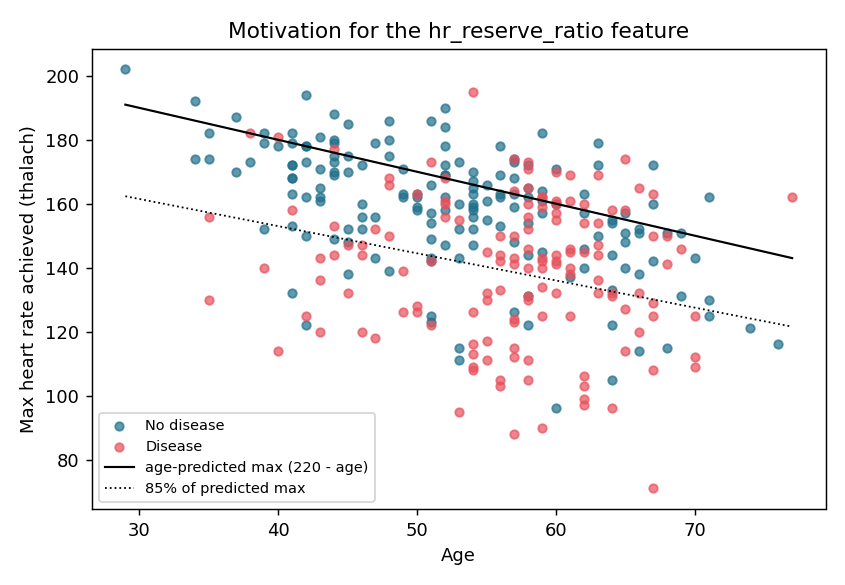

Spearman corr with target  thalach: -0.423  hr_reserve_ratio: -0.344


In [8]:
display(Image(filename=str(paths[6])))
ratio = clean['thalach'] / (220 - clean['age'])
print('Spearman corr with target  thalach: %.3f  hr_reserve_ratio: %.3f' % (
    clean['thalach'].corr(clean['target'], method='spearman'),
    ratio.corr(clean['target'], method='spearman')))

Max heart rate naturally declines with age, so raw `thalach` mixes two effects. Dividing by the age-predicted maximum (220 - age) gives the share of the expected maximum reached during the stress test (chronotropic response). It is implemented as the `ClinicalFeatureBuilder` transformer in `heart_risk/features.py`.